Simulate a AT schedule from a trajectory.
- Take in params
- output Simulated AT

Simulate a complete trial. 

In [1040]:
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
import shutil
import matplotlib

from at_modelling.LotkaVolterraModel import LotkaVolterraModel


Lets call instantiate a lotka volterra model. We can call the paramDic to see what params it has set

In [1041]:
#the model is set with default params
lv_model = LotkaVolterraModel()

print(f'Params:', lv_model.paramDic)
print(f'StateVars', lv_model.stateVars)

lv_model.SetParams()
lv_model.Simulate_AT(tumourSizeWhenProgressed=1.2)
lv_model.odeDF


Params: {'DMax': 1, 'rS': 0.027, 'rR': 0.027, 'K': 1, 'dD': 1.5, 'dS': 0.0, 'dR': 0.0, 'S0': 0.74, 'R0': 0.01, 'sigma': 0}
StateVars ['S', 'R']


,Time,DrugConcentration,S,R,TumourSize
0,0.000,1.0,0.740000,0.010000,0.750000
1,0.001,1.0,0.739998,0.010000,0.749998
2,0.002,1.0,0.739995,0.010000,0.749995
3,0.003,1.0,0.739993,0.010000,0.749993
4,0.004,1.0,0.739990,0.010000,0.749990
...,...,...,...,...,...
996,455.996,1.0,0.263583,0.636842,0.900425
997,455.997,1.0,0.263583,0.636843,0.900426
998,455.998,1.0,0.263583,0.636845,0.900428
999,455.999,1.0,0.263582,0.636847,0.900429


But it wont simulate yet. If you uncomment and run the following block, you should get an error that the model doesn't have an 'initialStateList'

In [1042]:
#model_example.Simulate_AT()

We can set our own initial state list, or simply call the Setparams which will get the values from the param dic (R0, S0). Note that a number of arguments can be passed 

We see that We can the print the results. The default time resolution is very high. We can clean the df to longer intervals and also be sure to remove post progression obs

## part 2
We can use the model simulate an entire trial. We can the use this data to test out inferential pipeline such as a bayesian fitting routine. We can add some makeshift, but the proper way to do it would be flexible model code. 

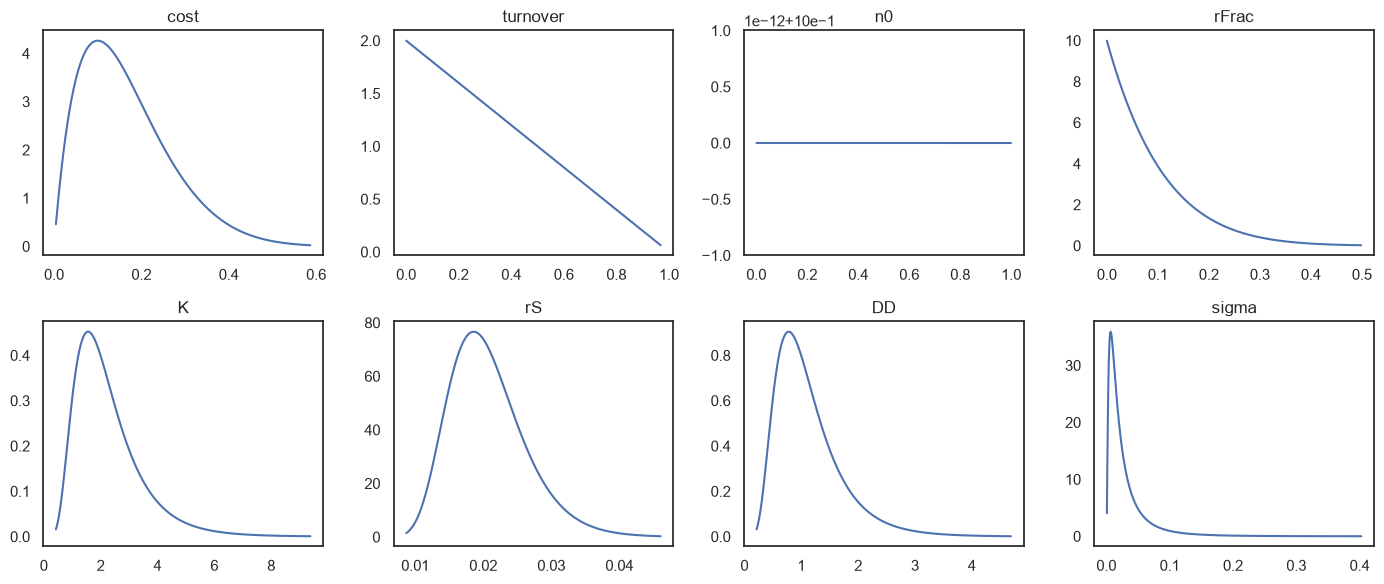

In [1043]:
priorDic = {
    "cost":     stats.beta(2, 10),
    "turnover": stats.beta(1, 2),
    "n0":       stats.beta(1, 1),
    "rFrac":    stats.beta(1, 10),
    "K":        stats.lognorm(s=0.5, scale=2),       
    "rS":       stats.lognorm(s=0.27, scale=0.02),
    "DD":       stats.lognorm(s = .5, scale = 1),
    'sigma':    stats.lognorm(s=1, scale=np.exp(-4)),  
}


def draw_params(priorDic : dict):
    """Contstruct a dictionary of sampled values from prior dict"""
    return {paramName: dist.rvs() for paramName, dist in priorDic.items()}

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    x = np.linspace(*dist.ppf([0.001, 0.999]), 400)
    ax.plot(x, dist.pdf(x)); ax.set_title(name)
plt.tight_layout()




In [1044]:
def add_cycle_col(Df, treatment_col):
    '''Function to add cycle identifier'''
    Df['Cycle'] = Df[treatment_col].ne(Df[treatment_col].shift()).cumsum()
    return Df

def random_params(paramRange):
    """Selects parameters randomly from output range"""
    output = {}
    for param in paramRange():
        if isinstance(paramRange[key], list):
            assert len(paramRange[key])==2, "Lists have upper and lower bound only"
            output[key] = np.random.uniform(*paramRange[key])
        else:
            output[key] = paramRange[key]
    return output

def complete_param_dict(cost, turnover, n0, rFrac, rS, K, DD, sigma):
    """Pass unpacked dict to generate param dict in
    form required by model class.
    N.B rS is a defualt value from literatue"""
    return {"Cost": cost, "Turnover": turnover,
                "n0": n0, "R0": rFrac * n0, "S0": (n0 - rFrac*n0),
                "rS": rS, "rR": rS * (1-cost),
                "dS": rS * turnover, "dR": rS * turnover,
                'K': K, 'dD': DD, 'sigma' : sigma}

def test_progression_at(model, t_end):
    """Selects for patients that reach progression (20% growth
    from initial size) within t_end days, under rule of thumb 
    AT treatment.
    """
    output = max(model.resultsDf['Time']) + day_interval < t_end
    return int(output)


# Generate random patients
n_patients = 1000
check_progression = True
t_end = 5000  # Ensure progression occurs in this period

#steady state check
def progress_on_ct(paramDic):
    """Return true if the params would even progress on continous therapy using the derivsation of Kit Gallagher'
    s DRL paper."""
    progressCTflag = paramDic['Turnover'] < (1 - 1.2 * (paramDic['S0']+paramDic['R0'])/paramDic['K']) * (1 - paramDic['Cost'])
    return(progressCTflag)


#setup path
out_dir = Path('../synth_data')
shutil.rmtree(out_dir, ignore_errors=True) #delete if exists
out_dir.mkdir(parents=True)\

for i in range(n_patients):
    #run loop until viable param combination is found
    while True:
        priorDrawDic = draw_params(priorDic)
        paramDic = complete_param_dict(**priorDrawDic)
        if not progress_on_ct(paramDic=paramDic):
            print("Analytically doesnt progress CT")
            continue
        model = LotkaVolterraModel(method='RK45', dt=1)
        model.SetParams(**paramDic)
        model.Simulate_AT(atThreshold=0.5, intervalLength=28, t_end=t_end)
        if not np.isnan(model.ttp) or not check_progression:
            print(f"Check passed or not checking progression on AT! Saving Patient {i} out of {n_patients}")
            break
        print("Check failed")
    #break out while loop and store found param combination
    model.odeDF.to_csv(f'../synth_data/patient_{i}_ODEdf.csv')
    obsDf = pd.DataFrame(model.obsList)
    obsDf = add_cycle_col(obsDf, 'DrugConcentration')
    obsDf.to_csv(f'../synth_data/patient_{i}_OBSdf.csv')
    
    priorDrawDic["PatientId"] = i
    if i == 0:
        df = pd.DataFrame(priorDrawDic, index=[0])
    else:
        df = pd.concat([df, pd.DataFrame(priorDrawDic, index=[i])])
df.to_csv(f"../synth_data/randSynthetic{n_patients}Patients.csv")



Check passed or not checking progression on AT! Saving Patient 0 out of 1000
Check passed or not checking progression on AT! Saving Patient 1 out of 1000
Check passed or not checking progression on AT! Saving Patient 2 out of 1000
Check passed or not checking progression on AT! Saving Patient 3 out of 1000
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 4 out of 1000
Check passed or not checking progression on AT! Saving Patient 5 out of 1000
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 6 out of 1000
Check passed or not checking progression on AT! Saving Patient 7 out of 1000
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 8 out of 1000
Check passed or not checking progression on AT! Saving Patient 9 out of 1000
Check passed or not checking progression on AT! Saving Patient 10 out of 1000
Analytically doesnt progress CT
Check passed or not chec

Lets plot the patients we just generated.

array([[<Axes: title={'center': 'Time'}>,
        <Axes: title={'center': 'Cycle'}>]], dtype=object)

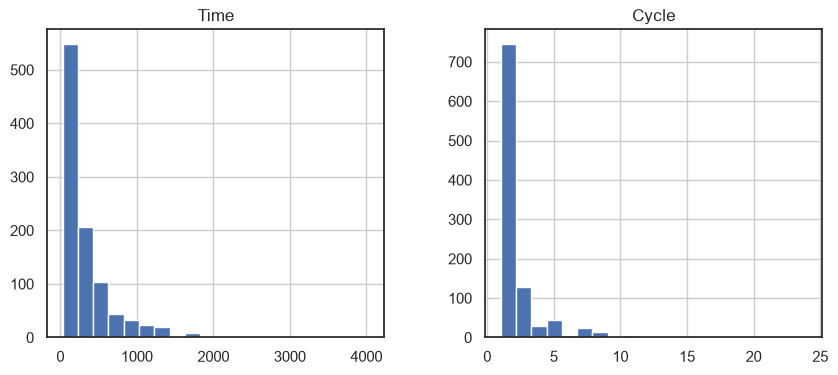

In [1045]:

import matplotlib.pyplot as plt



import glob
import re
files = glob.glob('../synth_data/*OBSdf.csv')
pattern = r'-?\d+\.?\d*'
dfs = [pd.read_csv(file) for file in files]
identifiers = [re.findall(pattern, file)[0] for file in files]
df = pd.concat([df.assign(PatientID = id) for id, df in zip(identifiers, dfs)]).reset_index(drop=True)

summary = df.groupby('PatientID').agg({'Time': 'max', 'Cycle': 'max' })
summary.hist(bins=20, figsize=(10, 4))


array([[<Axes: title={'center': 'Days'}>,
        <Axes: title={'center': 'Cycle'}>]], dtype=object)

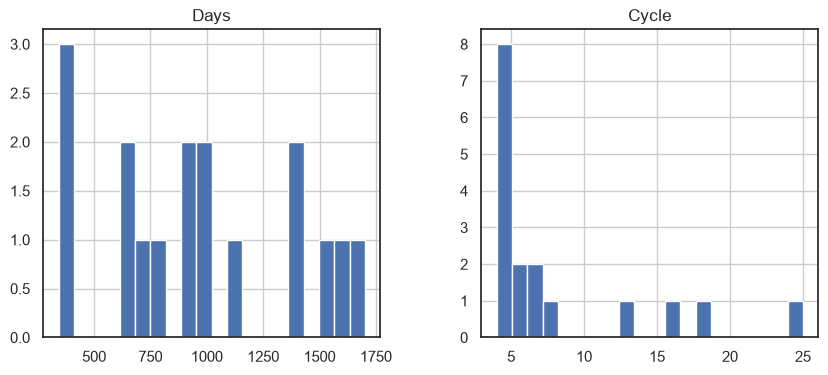

In [1046]:
import glob
import re
files = glob.glob('../data/*.csv')
pattern = r'-?\d+\.?\d*'
dfs = [pd.read_csv(file) for file in files]
dfs = [add_cycle_col(df, treatment_col='Abi') for df in dfs]
identifiers = [re.findall(pattern, file)[0] for file in files]
df = pd.concat([df.assign(PatientID = id) for id, df in zip(identifiers, dfs)]).reset_index(drop=True)

summary = df.groupby('PatientID').agg({'Days': 'max', 'Cycle': 'max' })
summary.hist(bins=20, figsize=(10, 4))


### part 3
Fit all of these using stan

In [1047]:
import cmdstanpy
